# 02 · Pipeline: history matching and production forecasting

**Team SPELUNCA · ExxonMobil DataWorks Challenge 2026**

## Purpose
This notebook runs the full method step by step, in the order the organisers suggested (Kick Off deck, slide 30):
**data preparation → ML proxy → optimization (history matching) → forecast → best 10 forecasts**, followed by the
parameter-influence analysis. Every step is written up in the same format:

| Part | Content |
|---|---|
| **Research question** | The sub-question (SRQ) the step answers, and our hypothesis |
| **Method** | What is done, with formula numbers from `research/04_formulas.md` |
| **Data used** | Which cases (train / validation / test) and which observations |
| **Results** | Tables and figures (also saved to `outputs/`) |
| **Findings** | Generated from the results when the notebook runs, so text and numbers always agree |
| **Hypothesis check** | Supported / not supported, with the evidence |
| **Discussion and limitations** | What the result means and what it does not show |

At the end, the notebook **answers every research question**.

## Main research question
> Can a physics-constrained machine-learning proxy, trained on 100 simulated reservoir cases, identify the
> reservoir parameters that are consistent with the field's observed 1998–2008 production history, and use them to
> forecast cumulative oil, gas and water production to 2028 with an honest uncertainty range?

| Step | Sub-question |
|---|---|
| 1. Data preparation | **SRQ1:** How should simulated and observed production be aligned in time? |
| 2. ML proxy | **SRQ4:** How accurately can an ML proxy reproduce the simulator for unseen cases? |
| 3. History matching | **SRQ2:** Which parameter values best match the observed history, and is the answer unique? |
| 4. Forecast | **SRQ5:** Can we forecast reliably 20 years beyond the data, and which method does it best? |
| 5. Best 10 | **SRQ6:** Which 10 forecasts best represent the field, and how much uncertainty remains? |
| 6. Parameter influence | **SRQ3:** Which of the four parameters control production, now and in the future? |

## Data and the train / validation / test rule
| Data | Role |
|---|---|
| Cases 1–70 (**train**) | Fit the proxy and the ML forecaster |
| Cases 71–85 (**validation**) | Every choice: proxy model, uncertainty calibration, water trend, forecasting method |
| Cases 86–100 (**test**) | Reported once, never used to fit or choose anything |
| Observed field 1998–2008 | Target of history matching; truth for the whole-pipeline backtest |

After all choices are made, the final proxy and forecasters are refitted on all 100 cases (more data for the real
field). The validation and test scores reported below come from the models fitted on the training cases only.

**Run time** about 2–4 minutes depending on the machine (most of it in Step 3); the last
code cell prints the actual time. **Confidentiality:** outputs contain competition data, so clear them before committing.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.report import log_to_file_only, millions, pct, sci, show_md, show_table, verdict

pd.set_option("display.max_columns", 50)
cfg = load_config(ROOT / "config.yaml", root=ROOT)   # data folder: DWC26_DATA_DIR in .env, else data/raw
print("Data folder:", cfg["paths"]["raw"])

Data folder: C:\SpeluncaDWC26trst\data\raw


In [2]:
# Run information: records the environment, so results from different machines can be compared
import platform
import time
from importlib.metadata import version

RUN_START = time.perf_counter()
print(f"Python {platform.python_version()} on {platform.system()} {platform.machine()}")
print(" | ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scipy", "scikit-learn", "SALib", "openpyxl")))
print(f"Random seed {cfg['project']['random_seed']} | started {time.strftime('%Y-%m-%d %H:%M')}")


Python 3.12.0 on Windows AMD64
numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | SALib 1.6.0 | openpyxl 3.1.5
Random seed 42 | started 2026-10-16 14:37


In [3]:
from src import deliverable, s1_prepare, s2_proxy, s3_history_match, s4_forecast, s5_best10, s6_sensitivity
from src.utils import PHASES, weighted_quantile

T, F = cfg["paths"]["tables"], cfg["paths"]["figures"]
names = cfg["parameters"]["names"]
state = {}
LABEL = {"decline": "decline-curve", "ml_autoregressive": "ML autoregressive", "naive": "naive",
         "wor_vs_np": "ln(WOR) vs cumulative oil", "wor_vs_time": "ln(WOR) vs time"}
# display names used in the result tables
SPLIT_NAME = {"validation": "Validation (cases 71–85)", "test": "Test (cases 86–100)"}
MODEL_NAME = {"pca_gp": "PCA + Gaussian process (ours)", "gboost_pca": "Gradient boosting on PCA",
              "linear": "Linear regression", "nearest_case": "Nearest simulated case"}
METHOD_NAME = {"decline": "Decline curve", "ml_autoregressive": "ML autoregressive"}
BT_METHOD_NAME = {"ml_autoregressive": "ML autoregressive", "decline_wor_vs_np": "Decline + ln(WOR) vs cum. oil",
                  "decline_wor_vs_time": "Decline + ln(WOR) vs time", "naive": "Naive (hold last rate)"}
PARAM_FMT = {"Fault Transmissibility": "{:.4f}", "Porosity Multiplier": "{:.4f}", "Permeability Multiplier": "{:.3f}",
             "Aquifer Pore Volume": "{:.2f}"}
log_to_file_only(cfg)   # step-by-step logs go to outputs/logs/pipeline.log; this notebook shows them as tables

---
## Step 1: Data preparation (SRQ1)

**Research question.** How should simulated and observed production be aligned in time?
**Hypothesis.** Observed rates are stamped at the *start* of their quarter; integrating them with that convention
removes the one-quarter offset seen in the raw data.

**Method.**
1. Read the 100 cases' cumulative curves and interpolate each onto the 41 observed dates (F20).
2. Integrate observed rates into cumulatives under both conventions, "start" and "end" (F22, real day counts).
3. Score every case against each version with the misfit (F23); the convention whose 10 best cases fit better is
   used. `RAMP_History` is compared as an independent check.
4. Quality checks: cumulatives never decrease, no negative values, gas–oil ratio constant.
5. Scale the 4 parameters (F28, permeability as ln) and attach the train / validation / test label.

**Data used.** All 100 cases (no fitting happens here) and the observed field.

In [4]:
state.update(s1_prepare.run(cfg))
conv = pd.read_csv(T / "srq1_convention_test.csv")
qc = pd.read_csv(T / "qc_report.csv")
show_table(conv.rename(columns={"convention": "Convention", "median_misfit_best10": "Median misfit, 10 best cases",
                                "min_misfit": "Lowest misfit", "best_case": "Best case",
                                "ramp_history_rel_diff_end": "RAMP_History difference at 2008"}),
           title="SRQ1: which date convention matches the simulator?",
           formats={"Median misfit, 10 best cases": "{:.3f}", "Lowest misfit": "{:.3f}",
                    "RAMP_History difference at 2008": sci(1)},
           highlight=conv["convention"].eq(state["convention"]).tolist(),
           note="Misfit = formula F23 (lower is better). RAMP_History difference = mean relative difference over "
                "oil, gas and water.")
show_table(qc.rename(columns={"check": "Check", "cases_failing": "Cases failing", "detail": "Detail"}),
           title="Data-quality checks on the 100 simulated cases")

Convention,"Median misfit, 10 best cases",Lowest misfit,Best case,RAMP_History difference at 2008
start,0.082,0.062,CASE 40,1.7e-08
end,6.900,6.773,CASE 19,2.6e-02


Check,Cases failing,Detail
oil: cumulative never decreases,0,n/a
oil: no negative values,0,n/a
gas: cumulative never decreases,0,n/a
gas: no negative values,0,n/a
water: cumulative never decreases,0,n/a
water: no negative values,0,n/a
gas/oil ratio within 2% of 0.3633 MSCF/STB,0,min=0.3632 median=0.3632 max=0.3633


In [5]:
c_best, c_other = conv.iloc[0], conv.iloc[1]
qc_fail = int(qc["cases_failing"].sum())
srq1_ok = c_best["convention"] == "start"
show_md(f"""**Findings**
- Median misfit of the 10 best cases: **{c_best['convention']} = {c_best['median_misfit_best10']:.3f}**,
  {c_other['convention']} = {c_other['median_misfit_best10']:.3f}, so the "{c_best['convention']}" convention fits
  **{c_other['median_misfit_best10'] / c_best['median_misfit_best10']:.0f}× better**.
- `RAMP_History` differs from the observed 2008 cumulative by {c_best['ramp_history_rel_diff_end']:.1e} under
  "{c_best['convention']}" vs {c_other['ramp_history_rel_diff_end']:.1e} under "{c_other['convention']}"
  (mean relative difference over oil, gas and water; `01_eda` §5 reports the largest of the three),
  which confirms it independently.
- Quality checks: **{qc_fail} failures** across {len(qc)} checks (cumulatives never decrease and are never negative,
  for each of oil, gas and water; gas–oil ratio within {cfg['gas']['rs_tolerance']:.0%} of {cfg['gas']['rs_expected']} MSCF/STB).
- Analysis-ready data: {len(state['obs_cum'])} dates × {state['features'].shape[0]} cases × 3 phases.

**Hypothesis check (SRQ1).** {verdict(srq1_ok)}. The observed rate on each date is the rate for the quarter
that *{c_best['convention']}s* on that date.""")

**Findings**
- Median misfit of the 10 best cases: **start = 0.082**,
  end = 6.900, so the "start" convention fits
  **85× better**.
- `RAMP_History` differs from the observed 2008 cumulative by 1.7e-08 under
  "start" vs 2.6e-02 under "end"
  (mean relative difference over oil, gas and water; `01_eda` §5 reports the largest of the three),
  which confirms it independently.
- Quality checks: **0 failures** across 7 checks (cumulatives never decrease and are never negative,
  for each of oil, gas and water; gas–oil ratio within 2% of 0.3633 MSCF/STB).
- Analysis-ready data: 41 dates × 100 cases × 3 phases.

**Hypothesis check (SRQ1).** **Supported**. The observed rate on each date is the rate for the quarter
that *starts* on that date.

**Discussion and limitations.** A one-quarter shift sounds small, but because volumes accumulate, the wrong
convention makes every case look like a worse match and would bias which parameters are selected. Testing both
conventions on the misfit, instead of assuming one, makes this choice evidence-based. The interpolation is exact
for volumes because cumulatives are interpolated, not rates.

---
## Step 2: ML proxy (SRQ4)

**Research question.** How accurately can an ML proxy reproduce the simulator for cases it has not seen?
**Hypothesis.** A PCA + Gaussian-process proxy reaches less than 5% error on cumulative oil at 2008, and its 80%
uncertainty band contains about 80% of held-out values.

**Why a proxy.** History matching needs tens of thousands of evaluations of "parameters → production". We do not
have the simulator, and it would be far too slow anyway. The proxy learns the mapping from the 100 runs and answers
almost instantly, *with an error bar* that the matching step uses.

**Method.**
1. For each phase, compress the 41-date cumulative curve with PCA (F29), keeping enough components to explain
   99.999% of the variance (at least 3).
2. Fit one Gaussian process per component on the 4 scaled parameters (Matérn 5/2 kernel, F30).
3. Predictive uncertainty = GP uncertainty + PCA truncation error, scaled per phase on validation cases so the
   80% band holds 80% of points (F47).
4. Compare with three baselines on the same split: linear regression, gradient boosting on the PCA scores, and the
   nearest simulated case.
5. Metrics: MAPE of the 2008 cumulative (F35), R² (F36), RMSE over the whole curve (F33), band coverage (F38).

**Pass criteria (set before running).** Accuracy: test MAPE of the 2008 oil cumulative below 5%. Uncertainty:
the calibrated 80% band holds 80% ± 5 percentage points of the test values.

**Data used.** Fit on train (1–70); compare and calibrate on validation (71–85); test (86–100) scored once.
The proxy used in Steps 3, 5 and 6 is then refitted on all 100 cases with the validated calibration.

**Reproducibility note.** Fitting a Gaussian process is a numerical optimisation, so band coverage and the scale
factors can move by a few tenths of a percentage point between machines and library builds (e.g. test coverage
77.8% on one machine, 78.2% on another). The accuracy figures move far less. The run-information cell at the top
records the environment of each run.

In [6]:
state.update(s2_proxy.run(cfg, state))
scores = pd.read_csv(T / "srq4_proxy_scores.csv")
unc = pd.read_csv(T / "srq4_proxy_uncertainty.csv")


def by_model(metric):
    """Split × model table of one metric, phases as columns, in a fixed readable order."""
    t = scores.pivot_table(index=["split", "model"], columns="phase", values=metric)[list(PHASES)]
    t = t.reindex(pd.MultiIndex.from_product([list(SPLIT_NAME), list(MODEL_NAME)]))
    t.index = pd.MultiIndex.from_tuples([(SPLIT_NAME[s], MODEL_NAME[m]) for s, m in t.index], names=["Split", "Model"])
    return t.rename(columns=str.capitalize)


ours = [(SPLIT_NAME[s], MODEL_NAME["pca_gp"]) for s in SPLIT_NAME]
show_table(by_model("mape_end_2008"), title="SRQ4: error of the 2008 cumulative on unseen cases (MAPE, %)",
           formats="{:.3f}", highlight=ours,
           note="Lower is better. Validation cases chose the model; test cases are reported once.")
show_table(by_model("r2_end_2008"), title="SRQ4: R² of the 2008 cumulative on unseen cases", formats="{:.4f}",
           highlight=ours, note="1 = perfect agreement with the simulator.")
show_table(unc.rename(columns={"raw_coverage_validation": "Raw coverage (validation)",
                               "sd_scale_oil_gas_water": "Scale factors oil / gas / water",
                               "calibrated_coverage_validation": "Calibrated coverage (validation)",
                               "calibrated_coverage_test": "Calibrated coverage (test)", "target": "Target"}),
           title="SRQ4: 80% uncertainty band: share of held-out values inside it",
           formats={"Raw coverage (validation)": "{:.1%}", "Calibrated coverage (validation)": "{:.1%}",
                    "Calibrated coverage (test)": "{:.1%}", "Target": "{:.0%}"},
           align={"Scale factors oil / gas / water": "right"})

Split,Model,Oil,Gas,Water
Validation (cases 71–85),PCA + Gaussian process (ours),0.023,0.020,0.104
,Gradient boosting on PCA,0.534,0.510,0.660
,Linear regression,0.860,0.857,0.953
,Nearest simulated case,1.597,1.600,3.770
Test (cases 86–100),PCA + Gaussian process (ours),0.038,0.038,0.094
,Gradient boosting on PCA,0.692,0.721,1.069
,Linear regression,1.109,1.102,1.238
,Nearest simulated case,3.682,3.682,6.190


Split,Model,Oil,Gas,Water
Validation (cases 71–85),PCA + Gaussian process (ours),1.0000,1.0000,0.9999
,Gradient boosting on PCA,0.9923,0.9924,0.9973
,Linear regression,0.9771,0.9772,0.9932
,Nearest simulated case,0.9439,0.9437,0.9297
Test (cases 86–100),PCA + Gaussian process (ours),1.0000,1.0000,0.9999
,Gradient boosting on PCA,0.9908,0.9900,0.9936
,Linear regression,0.9769,0.9771,0.9906
,Nearest simulated case,0.6977,0.6983,0.7037


Raw coverage (validation),Scale factors oil / gas / water,Calibrated coverage (validation),Calibrated coverage (test),Target
80.5%,1.0000 / 1.0013 / 1.0000,80.6%,77.8%,80%


In [7]:
px = state["proxy_train_only"]
v = scores[scores.split == "validation"].pivot(index="model", columns="phase", values="mape_end_2008")
t = scores[scores.split == "test"].pivot(index="model", columns="phase", values="mape_end_2008")
worst = scores[(scores.model == "pca_gp")].groupby("split")["worst_case_rel_err_end"].max()
base = v.drop(index="pca_gp")
px_gain = (base.min() / v.loc["pca_gp"])
cov_t = float(unc["calibrated_coverage_test"].iloc[0])
srq4_ok = t.loc["pca_gp", "oil"] < 5.0
cov_ok = abs(cov_t - 0.80) <= 0.05
show_md(f"""**Findings**
- PCA components kept per phase (oil, gas, water): **{px.k_}**, explaining
  {", ".join(f"{100 * e:.4f}%" for e in px.explained_)} of each phase's variance.
- Validation MAPE of the proxy: {", ".join(f"{k} **{v.loc['pca_gp', k]:.3f}%**" for k in PHASES)};
  best baseline: {", ".join(f"{k} {base[k].min():.3f}% ({base[k].idxmin()})" for k in PHASES)}.
  The proxy is **{px_gain.min():.0f}–{px_gain.max():.0f}× more accurate** than the best baseline.
- Test MAPE (reported once): {", ".join(f"{k} **{t.loc['pca_gp', k]:.3f}%**" for k in PHASES)};
  worst single test case (any phase): {pct(worst['test'], 2)} error at 2008.
- 80% band coverage: raw {pct(unc['raw_coverage_validation'].iloc[0])} on validation → calibrated
  {pct(unc['calibrated_coverage_validation'].iloc[0])} on validation and **{pct(cov_t)} on test**
  (scale factors {unc['sd_scale_oil_gas_water'].iloc[0]}).

**Hypothesis check (SRQ4).** Accuracy: {verdict(srq4_ok)} (test oil error {t.loc['pca_gp', 'oil']:.3f}% vs the 5% target).
Uncertainty: {verdict(cov_ok)} (test coverage {pct(cov_t)} vs 80% ± 5 points).""")

**Findings**
- PCA components kept per phase (oil, gas, water): **[5, 5, 5]**, explaining
  99.9995%, 99.9995%, 99.9995% of each phase's variance.
- Validation MAPE of the proxy: oil **0.023%**, gas **0.020%**, water **0.104%**;
  best baseline: oil 0.534% (gboost_pca), gas 0.510% (gboost_pca), water 0.660% (gboost_pca).
  The proxy is **6–26× more accurate** than the best baseline.
- Test MAPE (reported once): oil **0.038%**, gas **0.038%**, water **0.094%**;
  worst single test case (any phase): 0.56% error at 2008.
- 80% band coverage: raw 80.5% on validation → calibrated
  80.6% on validation and **77.8% on test**
  (scale factors 1.0000 / 1.0013 / 1.0000).

**Hypothesis check (SRQ4).** Accuracy: **Supported** (test oil error 0.038% vs the 5% target).
Uncertainty: **Supported** (test coverage 77.8% vs 80% ± 5 points).

**Discussion and limitations.**
- The proxy reproduces the **simulator**, not the real field: its accuracy says the matching step can trust it
  as a stand-in for simulation runs, not that the reservoir model itself is right.
- Accuracy is measured on 1998–2008 curves. The proxy is not asked to predict after 2008; the forecast is a
  separate step (Step 4).
- The per-phase PCA matters: with one shared PCA the weak parameters' effects were lost (recorded in
  `research/06_findings_log.md`). Keeping small components is what lets the proxy see aquifer and permeability.

---
## Step 3: Optimization / history matching (SRQ2)

**Research question.** Which parameter values minimise the mismatch with the observed history, and is the answer
unique?
**Hypotheses.** (a) A proxy-based optimum fits better than any of the 100 simulated cases. (b) Several distinct
parameter sets fit almost equally well (non-uniqueness). (c) The set of good cases is stable when the assumed
observation error changes.

**Method.**
1. **Loss function** (the deck asks us to "craft a loss function"): weighted least-squares misfit over all dates
   and phases (F23), with observation error 5% of the observed value (floor 1% of the phase maximum) and the proxy's
   own uncertainty added, so the optimiser cannot exploit proxy error.
2. **Baseline:** score the 100 simulated cases directly; accept the best 15%. Sensitivity: repeat with 3% and 10%.
3. **Optimum:** differential evolution on the proxy over the whole parameter range.
4. **Posterior:** 20,000 Latin-hypercube samples scored with the proxy; the best 500 are kept and weighted
   w ∝ exp(−misfit/2) (F24). Their spread measures how well each parameter is identified.

**Pass criteria (set before running).** (a) The optimum's misfit is lower than the best simulated case's.
(b) A parameter counts as **identified** if its posterior P10–P90 spans less than 25% of its design range and
**not identified** if it spans 50% or more; non-uniqueness is supported if at least one parameter is not identified.
(c) Stable if every accepted case stays accepted when σ is set to 3% and to 10%.

**Data used.** Observed field 1998–2008 (target). Final proxy (refitted on all 100 cases).

Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume,Misfit (proxy),Best simulated case misfit,Optimiser converged
0.1500,1.3021,9.785,53.95,0.0569,0.0619,Yes


Case,Misfit,Oil,Gas,Water,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume,Split
CASE 40,0.0619,0.0028,0.0029,0.0562,0.1443,1.3543,4.961,132.52,train
CASE 11,0.0622,0.0028,0.0028,0.0565,0.1250,1.3538,7.338,188.08,train
CASE 6,0.0694,0.0025,0.0024,0.0645,0.0577,1.3584,2.468,119.77,train
CASE 50,0.0751,0.0036,0.0036,0.0680,0.1003,1.3567,7.459,170.74,train
CASE 97,0.0808,0.0029,0.0029,0.0750,0.0519,1.3462,5.409,153.89,test
CASE 73,0.0824,0.0037,0.0042,0.0745,0.0826,1.3538,1.475,93.32,validation
CASE 76,0.0829,0.0032,0.0031,0.0767,0.1079,1.3833,1.640,182.20,validation
CASE 20,0.0891,0.0043,0.0044,0.0804,0.0618,1.3611,5.078,123.38,train
CASE 26,0.1309,0.0037,0.0041,0.1231,0.0980,1.3464,1.943,53.95,train
CASE 4,0.1627,0.0073,0.0074,0.1480,0.1455,1.3641,8.602,158.11,train


σ (share of observed value),Accepted cases,Also accepted at σ = 5%,Best case,Best misfit
5%,15,15,CASE 40,0.0619
3%,15,15,CASE 11,0.1214
10%,15,15,CASE 97,0.0320


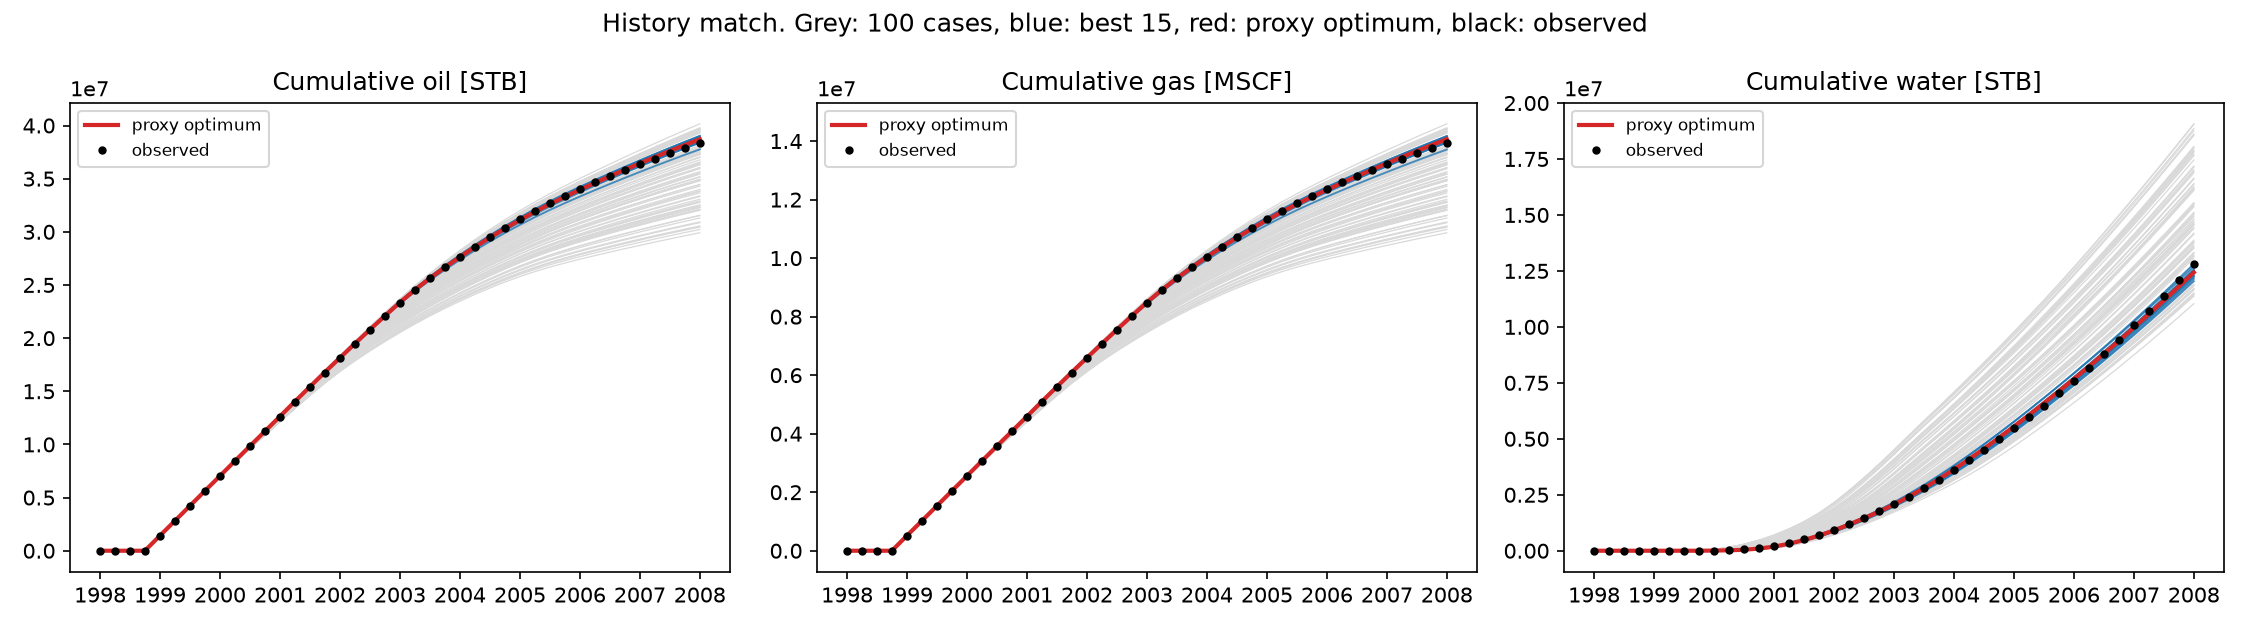

In [8]:
state.update(s3_history_match.run(cfg, state))
cm = pd.read_csv(T / "srq2_case_misfit.csv", index_col=0)
sens = pd.read_csv(T / "srq2_sigma_sensitivity.csv")
opt = pd.read_csv(T / "srq2_optimum.csv")
show_table(opt.rename(columns={"misfit_proxy": "Misfit (proxy)", "best_case_misfit_sim": "Best simulated case misfit",
                               "de_converged": "Optimiser converged"}),
           title="SRQ2: proxy optimum found by differential evolution",
           formats={**PARAM_FMT, "Misfit (proxy)": "{:.4f}", "Best simulated case misfit": "{:.4f}"})
top10 = cm.head(10)[["misfit", "misfit_oil", "misfit_gas", "misfit_water", *names, "split"]]
show_table(top10.rename(columns={"misfit": "Misfit", "misfit_oil": "Oil", "misfit_gas": "Gas", "misfit_water": "Water",
                                 "split": "Split"}).rename_axis("Case"),
           title="The 10 best-matching simulated cases (lowest misfit first)",
           formats={**{c: "{:.4f}" for c in ("Misfit", "Oil", "Gas", "Water")}, **PARAM_FMT},
           note="Misfit = formula F23 (lower is better). Oil, Gas and Water are its parts; they add up to the total.")
show_table(sens.rename(columns={"sigma_rel": "σ (share of observed value)", "n_accepted": "Accepted cases",
                                "overlap_with_base": f"Also accepted at σ = {cfg['matching']['sigma_rel']:.0%}",
                                "best_case": "Best case", "best_misfit": "Best misfit"}),
           title="Sensitivity of the accepted cases to the assumed observation error σ",
           formats={"σ (share of observed value)": "{:.0%}", "Best misfit": "{:.4f}"},
           highlight=sens["sigma_rel"].eq(cfg["matching"]["sigma_rel"]).tolist())
display(Image(F / "srq2_history_match.png"))

In [9]:
post = state["posterior"]
prior_lo, prior_hi = state["features"][names].min(), state["features"][names].max()
q = {n: weighted_quantile(post[n].to_numpy(), [0.1, 0.9], post["weight"].to_numpy()) for n in names}
ident = pd.DataFrame({
    "parameter": names,
    "design range": [f"{prior_lo[n]:.4g} – {prior_hi[n]:.4g}" for n in names],
    "posterior P10 – P90": [f"{q[n][0]:.4g} – {q[n][1]:.4g}" for n in names],
    "share of design range": [pct((q[n][1] - q[n][0]) / (prior_hi[n] - prior_lo[n]), 0) for n in names],
})
ident["share_value"] = [(q[n][1] - q[n][0]) / (prior_hi[n] - prior_lo[n]) for n in names]
x_opt = state["x_opt"]
edge = [n for n, x in zip(names, x_opt) if x < 0.01 or x > 0.99]
acc = cm[cm["accepted"]]
gain = 1 - opt["misfit_proxy"].iloc[0] / opt["best_case_misfit_sim"].iloc[0]
well = ident.loc[ident.share_value < 0.25, "parameter"].tolist()
poor = ident.loc[ident.share_value >= 0.5, "parameter"].tolist()
stable = int(sens["overlap_with_base"].min()) == int(sens["n_accepted"].iloc[0])
w_ratio = float(post["weight"].max() / post["weight"].min())
water_share = float((acc["misfit_water"] / acc["misfit"]).median())
show_md(f"""**Findings**
- Best simulated case: **{cm.index[0]}** (misfit {cm['misfit'].iloc[0]:.4f}). Proxy optimum: misfit
  **{opt['misfit_proxy'].iloc[0]:.4f}**, which is **{pct(gain)} lower** than the best simulated case
  (differential evolution converged: {bool(opt['de_converged'].iloc[0])}).
- Optimum parameters: {", ".join(f"{n} = {opt[n].iloc[0]:.4g}" for n in names)}.
  {"At the edge of the design range: **" + ", ".join(edge) + "**." if edge else "None at the edge of the design range."}
- Accepted simulated cases (best {len(acc)}): {acc['split'].value_counts().to_dict()}; water contributes a median
  **{pct(water_share, 0)}** of their misfit, so water is the hardest phase to match.
- Changing the observation error to {", ".join(f"{s:.0%}" for s in sens["sigma_rel"].iloc[1:])} keeps
  **{int(sens['overlap_with_base'].min())} of {int(sens['n_accepted'].iloc[0])}** accepted cases.
- Identifiability (weighted P10–P90 of the 500-sample posterior, as a share of the design range):""")
show_table(ident.drop(columns="share_value").set_index("parameter").rename_axis("Parameter")
           .rename(columns=lambda c: c[:1].upper() + c[1:]),
           title="Identifiability: weighted posterior P10–P90 as a share of the design range",
           align={"Design range": "right", "Posterior P10 – P90": "right", "Share of design range": "right"},
           highlight=well, note="Identified: under 25% of the design range. Not identified: 50% or more.")
show_md(f"""**Hypothesis check (SRQ2).**
- (a) Proxy optimum beats every simulated case: {verdict(gain > 0)}.
- (b) Non-uniqueness: {verdict(bool(poor))}. {", ".join(poor) or "no parameter"} {"remain" if len(poor) != 1 else "remains"} spread over at
  least half of the design range among equally good matches, while {", ".join(well) or "no parameter"} {"are" if len(well) != 1 else "is"} pinned to less than a quarter.
- (c) Stability to the error assumption: {verdict(stable)}.""")

**Findings**
- Best simulated case: **CASE 40** (misfit 0.0619). Proxy optimum: misfit
  **0.0569**, which is **8.1% lower** than the best simulated case
  (differential evolution converged: True).
- Optimum parameters: Fault Transmissibility = 0.15, Porosity Multiplier = 1.302, Permeability Multiplier = 9.785, Aquifer Pore Volume = 53.95.
  At the edge of the design range: **Fault Transmissibility, Permeability Multiplier, Aquifer Pore Volume**.
- Accepted simulated cases (best 15): {'train': 9, 'test': 3, 'validation': 3}; water contributes a median
  **91%** of their misfit, so water is the hardest phase to match.
- Changing the observation error to 3%, 10% keeps
  **15 of 15** accepted cases.
- Identifiability (weighted P10–P90 of the 500-sample posterior, as a share of the design range):

Parameter,Design range,Posterior P10 – P90,Share of design range
Fault Transmissibility,0.05011 – 0.15,0.05884 – 0.137,78%
Porosity Multiplier,0.8012 – 1.494,1.334 – 1.379,7%
Permeability Multiplier,0.5205 – 9.785,0.8296 – 7.924,77%
Aquifer Pore Volume,53.95 – 199.8,76.93 – 187.8,76%


**Hypothesis check (SRQ2).**
- (a) Proxy optimum beats every simulated case: **Supported**.
- (b) Non-uniqueness: **Supported**. Fault Transmissibility, Permeability Multiplier, Aquifer Pore Volume remain spread over at
  least half of the design range among equally good matches, while Porosity Multiplier is pinned to less than a quarter.
- (c) Stability to the error assumption: **Supported**.

In [10]:
show_md(f"""**Discussion and limitations.**
- {"The answer to *which parameters?* is **not a single set**. The history pins down " + ", ".join(well) +
   ", while " + ", ".join(poor) + " can trade off against each other with almost no change in the fit. This is the "
   "classic non-uniqueness of history matching, and it is why the forecast uses an ensemble (Steps 5–6) rather than "
   "one *best* model." if poor else "All parameters are well identified, so a single best model would be defensible."}
- {("The optimum lies on the edge of the design range for " + ", ".join(edge) + ". " +
    ("These are exactly the poorly identified parameters, so the misfit surface is almost flat along them and the "
     "optimiser's position on the edge is not a strong preference: equally good matches exist across their range "
     "(table above). " if set(edge) <= set(poor) else
     "Some of these are well identified, so the best fit may lie outside the range the organisers sampled. ") +
    "The proxy is only trusted inside the design range, so we do not extrapolate.")
   if edge else "The optimum lies inside the design range, so no extrapolation is needed."}
- Posterior weights w ∝ exp(−misfit/2) vary by only {w_ratio:.3f}× across the 500 kept samples, because the misfit
  is averaged over dates and is small for all good matches: the posterior is in effect the **best 500 of
  {cfg["optimization"]["lhs_samples"]:,} samples, almost equally weighted**.
- The observation error (5%) is an assumption; the sensitivity test shows the accepted set
  {"does not change" if stable else "changes"} when it is varied.
- Only production volumes are matched, because there is no pressure data (EDA §1).""")

**Discussion and limitations.**
- The answer to *which parameters?* is **not a single set**. The history pins down Porosity Multiplier, while Fault Transmissibility, Permeability Multiplier, Aquifer Pore Volume can trade off against each other with almost no change in the fit. This is the classic non-uniqueness of history matching, and it is why the forecast uses an ensemble (Steps 5–6) rather than one *best* model.
- The optimum lies on the edge of the design range for Fault Transmissibility, Permeability Multiplier, Aquifer Pore Volume. These are exactly the poorly identified parameters, so the misfit surface is almost flat along them and the optimiser's position on the edge is not a strong preference: equally good matches exist across their range (table above). The proxy is only trusted inside the design range, so we do not extrapolate.
- Posterior weights w ∝ exp(−misfit/2) vary by only 1.016× across the 500 kept samples, because the misfit
  is averaged over dates and is small for all good matches: the posterior is in effect the **best 500 of
  20,000 samples, almost equally weighted**.
- The observation error (5%) is an assumption; the sensitivity test shows the accepted set
  does not change when it is varied.
- Only production volumes are matched, because there is no pressure data (EDA §1).

---
## Step 4: Forecast beyond 2008 (SRQ5)

**Research question.** Can we forecast reliably 20 years beyond the data, and which method does it best?
**Hypotheses.** (a) Oil follows a hyperbolic Arps decline (0 ≤ b ≤ 1). (b) Water follows a ln(WOR)–cumulative-oil
trend. (c) Gas = Rs × oil. (d) A physics-based decline is the most reliable extrapolator.

**Pass criteria (set before running).** (a) Partly supported if more than half of the fits sit at the b = 1 cap
(b > 0.95). (b) Supported if the cumulative-oil trend has the lower validation water error of the two water trends.
(d) Supported if the decline method has the lower validation oil + water error.

**Why a backtest.** There is no simulated or observed production after 2008 (EDA §4), so a 2028 forecast cannot
be checked directly. Instead, each method is fitted on data **up to 2004 only** and asked to forecast 2004–2008,
where the truth is known. The method that does this best on **validation** cases is used for the real forecast.

**Methods compared.**
| Method | Oil | Water | Gas |
|---|---|---|---|
| Decline (physics-based) | Hyperbolic Arps fitted on the late history, restarted at the last rate (F16, F16a, F17) | ln(WOR) vs cumulative oil, or vs time (F18) | Rs × oil (F13) |
| ML autoregressive | Gradient-boosted next-quarter ratio, given parameters and current state (F48) | Same model, Δln(1+WOR) | Rs × oil |
| Naive benchmark | Last rate held constant | Last rate held constant | Last rate held constant |

**Selection rule** (F50): mean error of the 2004→2008 increment on validation cases. Water alone chooses the
water trend; oil + water chooses the method. The other method is kept to show **model-form uncertainty**.

**Data used.** ML forecaster trained on train cases (history to 2004); every method evaluated on validation and
test cases; choices made on validation only. Final forecasters refitted on all 100 full histories.

Method,Validation error (oil + water),Selected
Decline curve,13.2%,No
ML autoregressive,5.5%,Yes


Split,Method,Oil,Gas,Water
Validation (cases 71–85),ML autoregressive,3.7,3.6,7.3
,Decline + ln(WOR) vs cum. oil,6.5,6.5,19.9
,Decline + ln(WOR) vs time,6.5,6.5,103.6
,Naive (hold last rate),46.6,46.6,19.6
Test (cases 86–100),ML autoregressive,3.9,3.9,6.9
,Decline + ln(WOR) vs cum. oil,6.0,6.0,18.3
,Decline + ln(WOR) vs time,6.0,6.0,101.6
,Naive (hold last rate),47.2,47.2,19.1


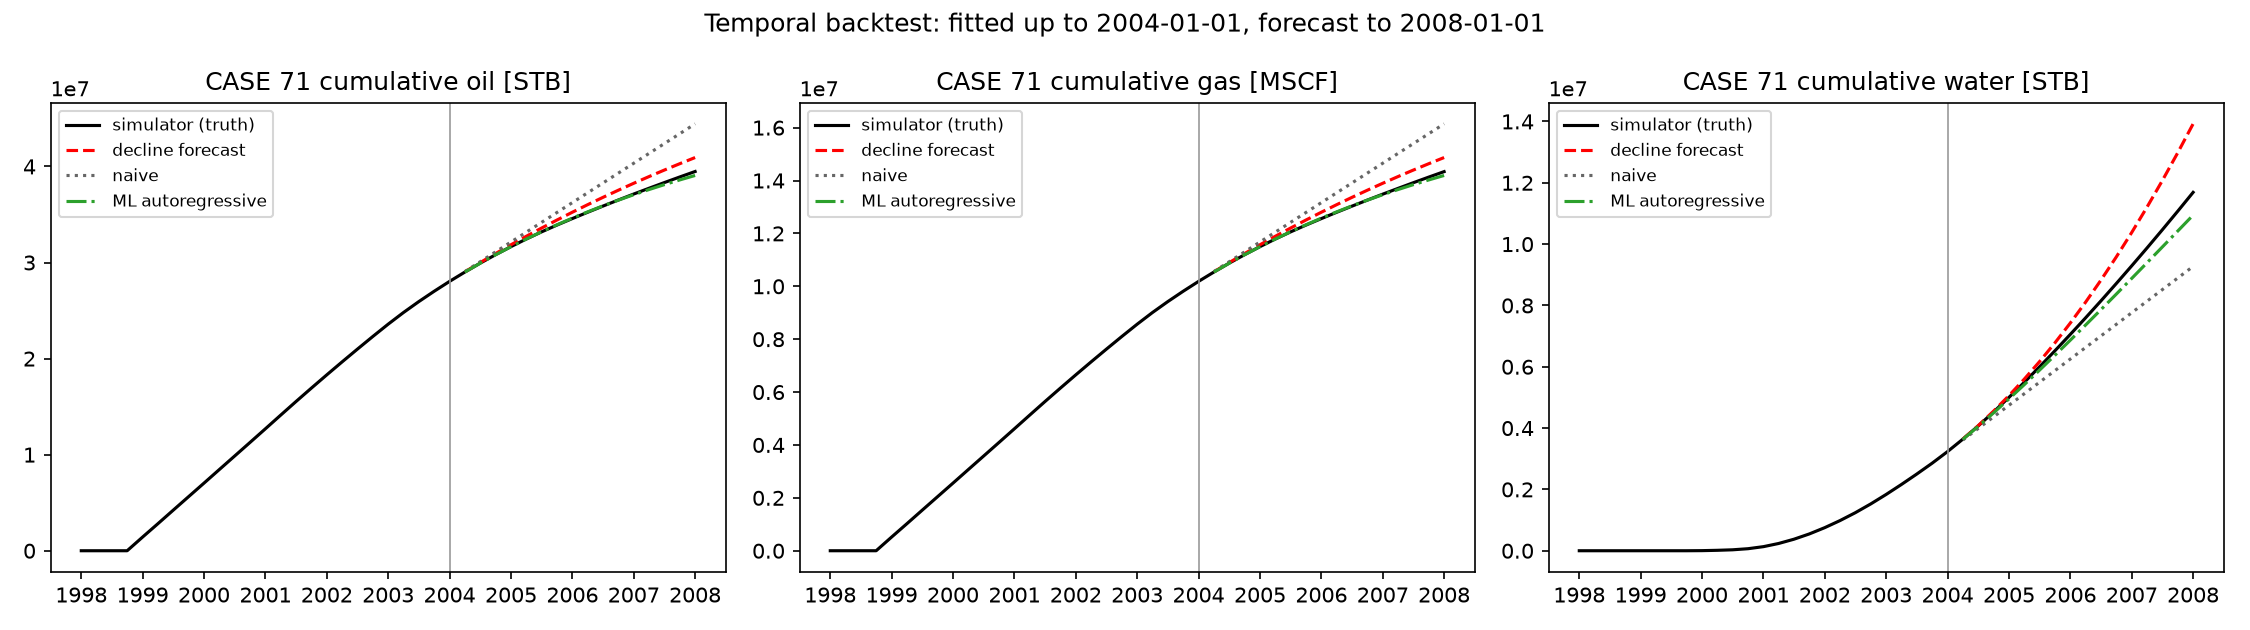

In [11]:
state.update(s4_forecast.run(cfg, state))
sel = pd.read_csv(T / "srq5_method_selection.csv")
show_table(sel.assign(method=sel["method"].map(METHOD_NAME)).rename(columns={
               "method": "Method", "validation_mean_increment_rel_err_oil_water": "Validation error (oil + water)",
               "selected": "Selected"}),
           title="SRQ5: forecasting method chosen on validation cases",
           formats={"Validation error (oil + water)": "{:.1%}"}, highlight=sel["selected"].astype(bool).tolist(),
           note="Mean error of the 2004→2008 increment (formula F50); lower is better.")
bt = state["backtest"]
bt_tab = (bt.groupby(["split", "method", "phase"])["increment_rel_err"].mean().unstack("phase")[list(PHASES)] * 100)
bt_show = bt_tab.reindex(pd.MultiIndex.from_product([list(SPLIT_NAME), list(BT_METHOD_NAME)]))
bt_show.index = pd.MultiIndex.from_tuples([(SPLIT_NAME[s], BT_METHOD_NAME[m]) for s, m in bt_show.index],
                                          names=["Split", "Method"])
chosen = "ml_autoregressive" if state["forecast_method"] == "ml_autoregressive" else f"decline_{state['water_model']}"
show_table(bt_show.rename(columns=str.capitalize), title="2004→2008 backtest: mean error of the increment (%)",
           formats="{:.1f}", highlight=[(SPLIT_NAME[s], BT_METHOD_NAME[chosen]) for s in SPLIT_NAME],
           note="Each method is fitted on data up to 2004 and forecasts 2004→2008; the simulator gives the truth.")
display(Image(F / "srq5_backtest.png"))

In [12]:
wm, method = state["water_model"], state["forecast_method"]
other = [m for m in ("decline", "ml_autoregressive") if m != method][0]
val = bt[bt.split == "validation"]
w_err = val[(val.phase == "water") & val.method.str.startswith("decline_")].groupby("method")["increment_rel_err"].mean()
m_err = sel.set_index("method")["validation_mean_increment_rel_err_oil_water"]
key = {"decline": f"decline_{wm}", "ml_autoregressive": "ml_autoregressive"}
tst = bt[bt.split == "test"]
t_err = {m: tst[(tst.method == key[m]) & tst.phase.isin(["oil", "water"])]["increment_rel_err"].mean() for m in key}
naive = val[(val.method == "naive") & val.phase.isin(["oil", "water"])]["increment_rel_err"].mean()
a28 = state["all_cases_2028"]
b_hi = float((a28["b"] > 0.95).mean())
ws = a28["water_source"].value_counts().to_dict()
same_on_test = min(t_err, key=t_err.get) == method
show_md(f"""**Findings**
- Water trend (decline method), validation error: {", ".join(f"{LABEL[k.removeprefix('decline_')]} **{pct(v)}**" for k, v in w_err.items())}
  → **{LABEL[wm]}** is used.
- Method, validation oil + water error: {", ".join(f"{LABEL[k]} **{pct(v)}**" for k, v in m_err.items())};
  naive benchmark {pct(naive)} → the **{LABEL[method]}** method is used; the {LABEL[other]} method is kept for model-form uncertainty.
- Test cases (not used for the choice): {", ".join(f"{LABEL[k]} {pct(v)}" for k, v in t_err.items())}.
  {"The same method wins, so the choice generalises" if same_on_test else "A different method wins on test, so the choice is not robust"}.
- Fitted Arps exponent b over the 100 cases: median **{a28['b'].median():.3f}**; **{pct(b_hi, 0)}** of cases have b > 0.95.
- Water model source over the 100 cases: {", ".join(f"{k.replace('_', ' ')} {n}" for k, n in ws.items())}.

**Hypothesis check (SRQ5).**
- Oil follows hyperbolic Arps with 0 ≤ b ≤ 1: {verdict(True, partly=b_hi > 0.5)}. The fits sit
  {"close to the upper bound b = 1 (harmonic decline)" if b_hi > 0.5 else "inside the range"}.
- Water follows ln(WOR) vs cumulative oil: {verdict(wm == "wor_vs_np")}.
- Gas = Rs × oil: {verdict(True)} (EDA §6; used by both methods).
- A physics-based decline is the most reliable extrapolator: {verdict(method == "decline")}. The
  {"decline" if method == "decline" else "ML autoregressive"} method has the lower backtest error.""")

**Findings**
- Water trend (decline method), validation error: ln(WOR) vs cumulative oil **19.9%**, ln(WOR) vs time **103.6%**
  → **ln(WOR) vs cumulative oil** is used.
- Method, validation oil + water error: decline-curve **13.2%**, ML autoregressive **5.5%**;
  naive benchmark 33.1% → the **ML autoregressive** method is used; the decline-curve method is kept for model-form uncertainty.
- Test cases (not used for the choice): decline-curve 12.2%, ML autoregressive 5.4%.
  The same method wins, so the choice generalises.
- Fitted Arps exponent b over the 100 cases: median **0.994**; **100%** of cases have b > 0.95.
- Water model source over the 100 cases: fit 100.

**Hypothesis check (SRQ5).**
- Oil follows hyperbolic Arps with 0 ≤ b ≤ 1: **Partly supported**. The fits sit
  close to the upper bound b = 1 (harmonic decline).
- Water follows ln(WOR) vs cumulative oil: **Supported**.
- Gas = Rs × oil: **Supported** (EDA §6; used by both methods).
- A physics-based decline is the most reliable extrapolator: **Not supported**. The
  ML autoregressive method has the lower backtest error.

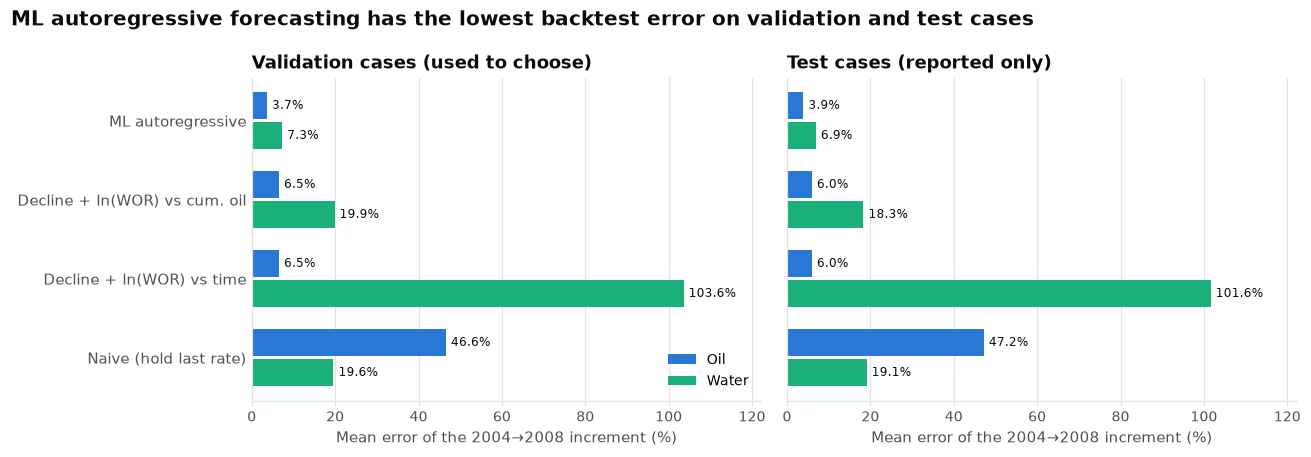

In [13]:
# All validation and test cases, not one: mean error of the 2004→2008 increment per method (F50)
from src.plotting import INK, PHASE_COLORS, SLIDE_RC, clean_axes, plt, png_bytes

plt.rcParams.update(SLIDE_RC)
M_ORDER = ["ml_autoregressive", f"decline_{wm}", f"decline_{[w for w in ('wor_vs_np', 'wor_vs_time') if w != wm][0]}", "naive"]
M_NAME = {"ml_autoregressive": "ML autoregressive", "naive": "Naive (hold last rate)",
          "decline_wor_vs_np": "Decline + ln(WOR) vs cum. oil", "decline_wor_vs_time": "Decline + ln(WOR) vs time"}
err = bt.groupby(["split", "method", "phase"])["increment_rel_err"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
xmax = float(err.loc[(slice(None), M_ORDER, ["oil", "water"])].max()) * 1.18
y = np.arange(len(M_ORDER))[::-1]
for ax, split in zip(axes, ("validation", "test")):
    for j, ph in enumerate(("oil", "water")):
        vals = [err.loc[(split, m, ph)] for m in M_ORDER]
        yy = y + (0.5 - j) * 0.38
        ax.barh(yy, vals, height=0.34, color=PHASE_COLORS[ph], label=ph.capitalize())
        for yi, v in zip(yy, vals):
            ax.text(v + xmax * 0.01, yi, f"{v:.1f}%", va="center", fontsize=8, color=INK)
    ax.set_yticks(y, [M_NAME[m] for m in M_ORDER])
    ax.set_xlim(0, xmax)
    ax.set_xlabel("Mean error of the 2004→2008 increment (%)")
    ax.set_title(f"{split.capitalize()} cases ({'used to choose' if split == 'validation' else 'reported only'})")
    clean_axes(ax, "x")
axes[0].legend(loc="lower right")
title = f"{LABEL[method][0].upper()}{LABEL[method][1:]} forecasting has the lowest backtest error on validation"
fig.suptitle(title + (" and test cases" if same_on_test else " cases, but not on test cases"),
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(F / "srq5_backtest_methods.png", dpi=150, bbox_inches="tight")
display(Image(data=png_bytes(fig)))
plt.close(fig)


In [14]:
dec_hi = float((a28["cum_oil_2028_decline"] > a28["cum_oil_2028_ml"]).mean())
show_md(f"""**Discussion and limitations.**
- The backtest covers 4 years; the real forecast covers 20. A method that wins over 4 years is the best evidence
  available, but it is not proof over 20. That is why both methods are carried forward and their difference is
  reported as model-form uncertainty in Step 5.
- {("All" if b_hi == 1 else "Most") + " fitted b values are close to 1, i.e. the decline is flattening (harmonic-like). Values above 1 are not "
   "allowed: for b ≥ 1 cumulative oil never levels off, which is not physical for a finite reservoir, so b = 1 is "
   "the physical limit and the fits sit at it." if b_hi > 0.5 else
   "Fitted b values lie inside 0–1, so the bound is not active."}
- The decline method gives more 2028 oil than the ML method in **{pct(dec_hi, 0)}** of the 100 cases, so the choice
  of method changes the forecast {"systematically" if dec_hi > 0.8 or dec_hi < 0.2 else "case by case"}.
- Both methods keep the physics: rates stay positive, cumulatives never decrease (F46), and gas follows oil at the
  measured ratio.
- Operations are assumed to continue as in 2008 (no new wells, workovers or changes in injection).""")

**Discussion and limitations.**
- The backtest covers 4 years; the real forecast covers 20. A method that wins over 4 years is the best evidence
  available, but it is not proof over 20. That is why both methods are carried forward and their difference is
  reported as model-form uncertainty in Step 5.
- All fitted b values are close to 1, i.e. the decline is flattening (harmonic-like). Values above 1 are not allowed: for b ≥ 1 cumulative oil never levels off, which is not physical for a finite reservoir, so b = 1 is the physical limit and the fits sit at it.
- The decline method gives more 2028 oil than the ML method in **100%** of the 100 cases, so the choice
  of method changes the forecast systematically.
- Both methods keep the physics: rates stay positive, cumulatives never decrease (F46), and gas follows oil at the
  measured ratio.
- Operations are assumed to continue as in 2008 (no new wells, workovers or changes in injection).

---
## Step 5: Best 10 forecasts and uncertainty (SRQ6)

**Research question.** Which 10 history-matched realisations best represent the field, and how much forecast
uncertainty remains?
**Hypotheses.** Matching narrows the 2028 range compared with all 100 cases, but a meaningful range remains; the
posterior P10–P90 band contains about 80% of observed values in the whole-pipeline backtest.

**Method.**
1. From the 500-sample posterior, pick the 10 lowest-misfit parameter sets that are at least 0.05 apart in scaled
   parameter space (F49). This gives 10 genuinely different realisations, not near-copies of one.
2. Forecast each from the **observed** 2008 cumulatives with the method chosen in Step 4 (F15), and with the other
   method for comparison.
3. P90 / P50 / P10 (F45) across the best 10 (equal weights) and across the weighted posterior; compare with the
   spread of all 100 unmatched cases.
4. **Whole-pipeline backtest against the real field:** match on observed data up to 2004 only, pick the best 10,
   forecast 2004–2008, compare with what the field actually produced (P50 error and band coverage, F38).
5. Business table: remaining oil 2008–2028, 2028 rates, water cut (F40), oil per pore volume (F42).

**Pass criteria (set before running).** Matching narrows the range if the posterior P10–P90 is narrower than that
of all 100 cases for every phase. A meaningful range remains if the posterior P10–P90 is at least 5% of its P50 for
every phase (partly supported otherwise). The band holds ~80% if its backtest coverage is within 80% ± 15 percentage
points for every phase.

**Data used.** Posterior from Step 3, forecasters from Step 4, observed field (start point and backtest truth).

Template sheet,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume,Misfit,Oil 2028 (M STB),Gas 2028 (M MSCF),Water 2028 (M STB)
Case 1,0.1500,1.3021,9.785,53.95,0.0569,58.91,21.40,79.86
Case 2,0.1181,1.3087,9.297,62.11,0.0581,59.04,21.45,80.50
Case 3,0.0686,1.3146,8.020,64.33,0.0595,59.01,21.44,79.40
Case 4,0.1284,1.3379,9.610,156.67,0.0596,59.44,21.59,81.35
Case 5,0.1332,1.3181,6.764,61.84,0.0597,58.91,21.40,79.48
Case 6,0.0826,1.3278,9.083,103.56,0.0599,59.33,21.55,81.71
Case 7,0.1336,1.3405,4.602,88.73,0.0599,58.89,21.39,79.70
Case 8,0.0802,1.3305,4.720,66.37,0.0600,58.77,21.34,80.13
Case 9,0.0592,1.3248,7.459,78.20,0.0601,59.02,21.44,79.48
Case 10,0.1383,1.3212,8.094,79.04,0.0602,59.05,21.45,79.46


Phase,Set,P90 (low),P50,P10 (high),P10–P90 width
Oil,All 100 cases (before matching),42.45,52.25,61.30,18.85
,Matched posterior,58.44,59.01,59.49,1.05
,"Best 10, ML autoregressive",58.83,59.01,59.38,0.55
,"Best 10, decline-curve",61.02,61.28,61.43,0.40
Gas,All 100 cases (before matching),15.42,18.98,22.26,6.84
,Matched posterior,21.22,21.44,21.61,0.39
,"Best 10, ML autoregressive",21.36,21.44,21.57,0.21
,"Best 10, decline-curve",22.16,22.26,22.32,0.15
Water,All 100 cases (before matching),77.29,84.90,98.48,21.19
,Matched posterior,78.75,79.96,81.23,2.48


Phase,Set,P10–P90 band coverage,P50 error at 2008,P50 error of the 2004→2008 increment
Oil,Best 10,0.0%,0.8%,2.8%
,Matched posterior,0.0%,1.0%,3.7%
Gas,Best 10,0.0%,0.8%,2.7%
,Matched posterior,0.0%,1.0%,3.7%
Water,Best 10,6.2%,5.7%,7.9%
,Matched posterior,6.2%,5.6%,7.8%


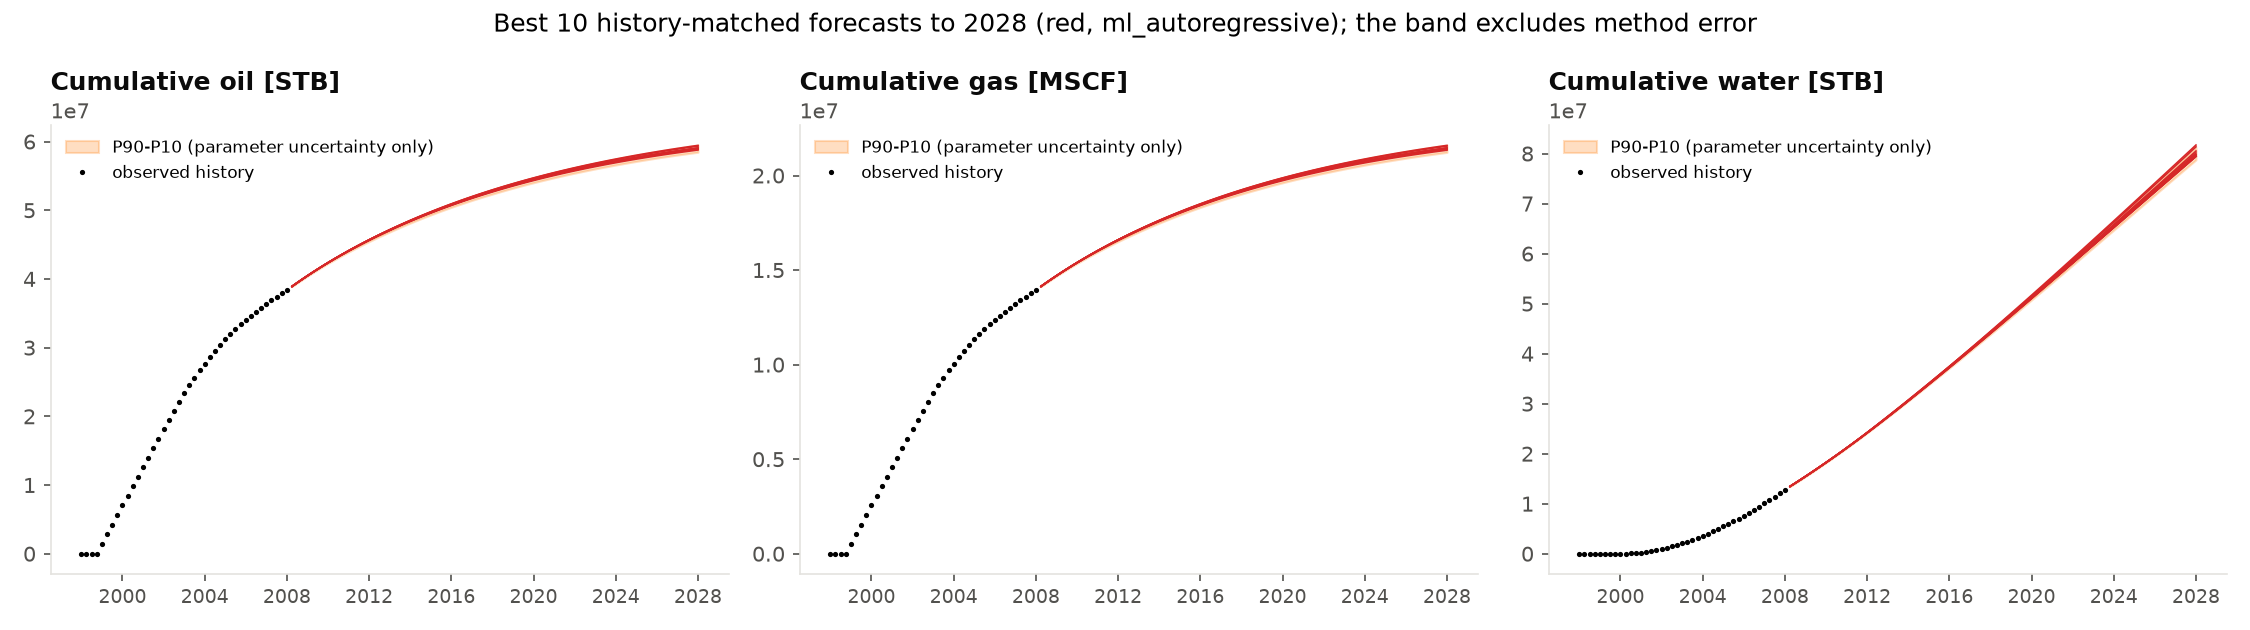

In [15]:
state.update(s5_best10.run(cfg, state))
best = pd.read_csv(T / "srq6_best10.csv")
spread = pd.read_csv(T / "srq6_spread_2028.csv")
pbt = pd.read_csv(T / "srq6_pipeline_backtest.csv")
b_show = best.set_index("template_sheet")[[*names, "misfit_proxy"]].rename(columns={"misfit_proxy": "Misfit"})
for k, unit in (("oil", "M STB"), ("gas", "M MSCF"), ("water", "M STB")):
    b_show[f"{k.capitalize()} 2028 ({unit})"] = best.set_index("template_sheet")[f"cum_{k}_2028"] / 1e6
show_table(b_show.rename_axis("Template sheet"),
           title="SRQ6: the 10 best history-matched forecasts (Case 1 = best match)",
           formats={**PARAM_FMT, "Misfit": "{:.4f}",
                    **{c: "{:.2f}" for c in b_show.columns if "2028" in c}},
           note=f"Cumulative production on 1 Jan 2028, {LABEL[method]} forecast.")
SET_NAME = {"all_100_cases": "All 100 cases (before matching)", "posterior": "Matched posterior",
            "best_10": f"Best 10, {LABEL[method]}", f"best_10_{other}": f"Best 10, {LABEL[other]}"}
sp_show = spread.set_index(["phase", "set"])[["P90_low", "P50", "P10_high", "P10_P90_width"]] / 1e6
sp_show.index = pd.MultiIndex.from_tuples([(p.capitalize(), SET_NAME[s]) for p, s in sp_show.index],
                                          names=["Phase", "Set"])
show_table(sp_show.rename(columns={"P90_low": "P90 (low)", "P10_high": "P10 (high)", "P10_P90_width": "P10–P90 width"}),
           title="2028 cumulative ranges: million STB (oil, water) or million MSCF (gas)", formats="{:,.2f}",
           highlight=[(p.capitalize(), SET_NAME["best_10"]) for p in PHASES],
           note="Ranges cover parameter uncertainty only; the two 'Best 10' rows differ by forecasting method.")
PBT_SET = {"best_10": "Best 10", "posterior": "Matched posterior"}
pb_show = pbt.set_index(["phase", "set"])
pb_show.index = pd.MultiIndex.from_tuples([(p.capitalize(), PBT_SET[s]) for p, s in pb_show.index],
                                          names=["Phase", "Set"])
show_table(pb_show.rename(columns={"coverage_p10_p90": "P10–P90 band coverage", "p50_rel_err_2008": "P50 error at 2008",
                                   "p50_increment_rel_err": "P50 error of the 2004→2008 increment"}),
           title="Whole-pipeline backtest against the real field (match ≤ 2004, forecast 2004→2008)",
           formats="{:.1%}")
display(Image(F / "srq6_forecast_fan.png"))

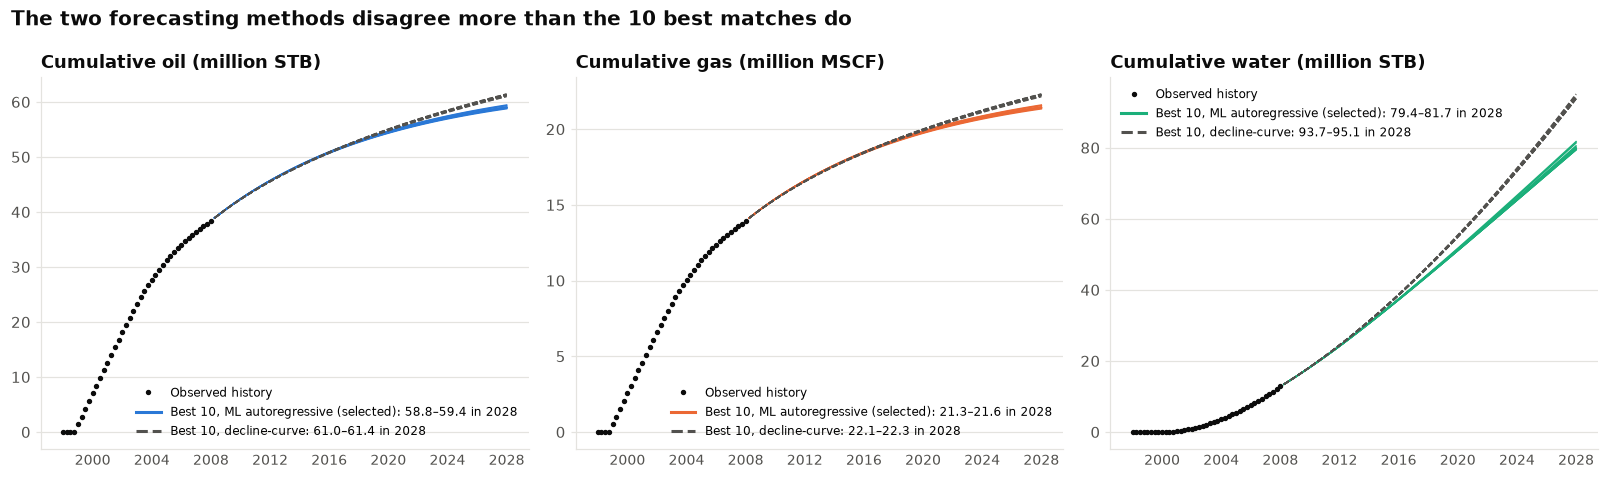

In [16]:
# The 10 deliverable forecasts with BOTH methods: the gap between methods is the main remaining uncertainty
from src.plotting import INK, INK_2, PHASE_COLORS, SLIDE_RC, clean_axes, plt, png_bytes
from src.utils import UNITS

plt.rcParams.update(SLIDE_RC)
f_dates = state["forecast_dates"]
anchor = {k: float(state["obs_cum"][k].iloc[-1]) for k in PHASES}
post, b10 = state["posterior"], cfg["best10"]   # the same 10 parameter sets Step 5 picked (same function, same inputs)
pxc = [c for c in post.columns if c.startswith("x") and c[1:].isdigit()]
X10 = post[pxc].to_numpy()[s5_best10.pick_diverse(post[pxc].to_numpy(), post["misfit_proxy"].to_numpy(),
                                                  b10["n_cases"], b10["min_distance"])]
fc_sel = state["best10_forecasts"]
fc_oth = s5_best10.forecast_param_sets(X10, state["proxy"], state["obs_cum"].index, f_dates, cfg,
                                       state["wor_fallback"], state["water_model"], anchor,
                                       method=other, ar_models=state["ar_models"])
for k in PHASES:   # same numbers as the table in srq6_best10.csv
    assert np.allclose(fc_oth[k][:, -1], state["best10"][f"cum_{k}_2028_{other}"], rtol=1e-9)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, k in zip(axes, PHASES):
    ax.plot(state["obs_cum"].index, state["obs_cum"][k] / 1e6, "o", color=INK, ms=2.5, label="Observed history")
    ax.plot(f_dates, fc_sel[k].T / 1e6, color=PHASE_COLORS[k], lw=1.0)
    ax.plot(f_dates, fc_oth[k].T / 1e6, color=INK_2, lw=1.0, ls="--")
    for fc, style, name in ((fc_sel, dict(color=PHASE_COLORS[k]), f"{LABEL[method]} (selected)"),
                            (fc_oth, dict(color=INK_2, ls="--"), LABEL[other])):
        ax.plot([], [], lw=2, **style,
                label=f"Best 10, {name}: {fc[k][:, -1].min() / 1e6:.1f}–{fc[k][:, -1].max() / 1e6:.1f} in 2028")
    ax.set_title(f"Cumulative {k} (million {UNITS[k]})")
    ax.legend(loc="upper left" if k == "water" else "lower right", fontsize=8)   # the empty corner of each panel
    clean_axes(ax, "y")
fig.suptitle("The two forecasting methods disagree more than the 10 best matches do",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(F / "srq6_methods_fan.png", dpi=150, bbox_inches="tight")
display(Image(data=png_bytes(fig)))
plt.close(fig)


In [17]:
sp = spread.set_index(["phase", "set"])
w = {k: sp.loc[(k, "all_100_cases"), "P10_P90_width"] / sp.loc[(k, "posterior"), "P10_P90_width"] for k in PHASES}
gap = {k: abs(sp.loc[(k, "best_10"), "P50"] - sp.loc[(k, f"best_10_{other}"), "P50"]) for k in PHASES}
ratio_gap = {k: gap[k] / sp.loc[(k, "posterior"), "P10_P90_width"] for k in PHASES}
pb = pbt.set_index(["phase", "set"])
cov = {k: pb.loc[(k, "posterior"), "coverage_p10_p90"] for k in PHASES}
narrower = all(r > 1 for r in w.values())
rem_share = {k: sp.loc[(k, "posterior"), "P10_P90_width"] / sp.loc[(k, "posterior"), "P50"] for k in PHASES}
cov_ok = all(abs(c - 0.8) <= 0.15 for c in cov.values())
rem = best["oil_2008_2028_stb"]
show_md(f"""**Findings**
- Best 10 parameters: {", ".join(f"{n} {best[n].min():.4g}–{best[n].max():.4g}" for n in names)}.
- 2028 P50 cumulative (best 10, {LABEL[method]} method): {", ".join(f"{k} **{millions(sp.loc[(k, 'best_10'), 'P50'])}**" for k in PHASES)}
  (STB for oil and water, MSCF for gas).
- History matching narrows the P10–P90 range by **{min(w.values()):.0f}–{max(w.values()):.0f}×** compared with all
  100 unmatched cases.
- Model-form uncertainty: the {LABEL[other]} method's best-10 P50 differs by {", ".join(f"{k} {millions(gap[k])} ({ratio_gap[k]:.1f}× the posterior width)" for k in PHASES)}.
- Whole-pipeline backtest (match ≤ 2004, forecast 2004–2008, vs the real field): P50 error at 2008
  {", ".join(f"{k} **{pct(pb.loc[(k, 'best_10'), 'p50_rel_err_2008'])}**" for k in PHASES)}; posterior band coverage
  {", ".join(f"{k} {pct(cov[k], 0)}" for k in PHASES)}.
- Remaining oil 2008–2028 across the best 10: **{millions(rem.min(), 2)}–{millions(rem.max(), 2)} STB**; water cut in 2028
  {pct(best['water_cut_2028'].min())}–{pct(best['water_cut_2028'].max())}; WOR cap reached in {int(best['wor_cap_reached'].sum())} of 10.

**Hypothesis check (SRQ6).**
- Matching narrows the range: {verdict(narrower)}.
- A meaningful range remains: {verdict(min(rem_share.values()) >= 0.05, partly=min(rem_share.values()) < 0.05)}. The
  posterior P10–P90 range is {", ".join(f"{k} {pct(rem_share[k])}" for k in PHASES)} of its P50;
  {"the difference between forecasting methods is larger than this parameter range, so most of the remaining uncertainty is model-form" if max(ratio_gap.values()) >= 1 else "parameter uncertainty is larger than the difference between methods"}.
- The band holds ~80% of observed values: {verdict(cov_ok)}. Coverage: {", ".join(f"{k} {pct(cov[k], 0)}" for k in PHASES)}.""")

**Findings**
- Best 10 parameters: Fault Transmissibility 0.05925–0.15, Porosity Multiplier 1.302–1.341, Permeability Multiplier 4.602–9.785, Aquifer Pore Volume 53.95–156.7.
- 2028 P50 cumulative (best 10, ML autoregressive method): oil **59.0 M**, gas **21.4 M**, water **79.8 M**
  (STB for oil and water, MSCF for gas).
- History matching narrows the P10–P90 range by **9–18×** compared with all
  100 unmatched cases.
- Model-form uncertainty: the decline-curve method's best-10 P50 differs by oil 2.3 M (2.2× the posterior width), gas 0.8 M (2.1× the posterior width), water 14.4 M (5.8× the posterior width).
- Whole-pipeline backtest (match ≤ 2004, forecast 2004–2008, vs the real field): P50 error at 2008
  oil **0.8%**, gas **0.8%**, water **5.7%**; posterior band coverage
  oil 0%, gas 0%, water 6%.
- Remaining oil 2008–2028 across the best 10: **20.39 M–21.06 M STB**; water cut in 2028
  89.8%–90.2%; WOR cap reached in 0 of 10.

**Hypothesis check (SRQ6).**
- Matching narrows the range: **Supported**.
- A meaningful range remains: **Partly supported**. The
  posterior P10–P90 range is oil 1.8%, gas 1.8%, water 3.1% of its P50;
  the difference between forecasting methods is larger than this parameter range, so most of the remaining uncertainty is model-form.
- The band holds ~80% of observed values: **Not supported**. Coverage: oil 0%, gas 0%, water 6%.

In [18]:
show_md(f"""**Discussion and limitations.**
- {"Matching removes most of the **parameter** uncertainty: the remaining parameter combinations give similar "
   "forecasts, and what remains is mostly **model-form** uncertainty (the choice of how to extrapolate), which the "
   "P10–P90 band does not include." if max(ratio_gap.values()) >= 1 else
   "Parameter uncertainty remains larger than the difference between forecasting methods."} Both are reported;
  the band is **not** claimed to be a full confidence interval.
- The whole-pipeline backtest is the strongest evidence here: it tests the entire method against the **real field**,
  not the simulator. Its P50 error ({", ".join(f"{k} {pct(pb.loc[(k, 'best_10'), 'p50_rel_err_2008'])}" for k in PHASES)})
  shows how accurate the method is; its band coverage ({", ".join(f"{k} {pct(cov[k], 0)}" for k in PHASES)})
  {"shows the band is too narrow once model error is ignored. That is an honest result a reviewer should see" if not cov_ok
   else "is close to the 80% target"}.
- The forecast starts from the observed 2008 cumulatives, so the template begins exactly where the field is.""")

**Discussion and limitations.**
- Matching removes most of the **parameter** uncertainty: the remaining parameter combinations give similar forecasts, and what remains is mostly **model-form** uncertainty (the choice of how to extrapolate), which the P10–P90 band does not include. Both are reported;
  the band is **not** claimed to be a full confidence interval.
- The whole-pipeline backtest is the strongest evidence here: it tests the entire method against the **real field**,
  not the simulator. Its P50 error (oil 0.8%, gas 0.8%, water 5.7%)
  shows how accurate the method is; its band coverage (oil 0%, gas 0%, water 6%)
  shows the band is too narrow once model error is ignored. That is an honest result a reviewer should see.
- The forecast starts from the observed 2008 cumulatives, so the template begins exactly where the field is.

In [19]:
# Why do the two methods differ? Gradient-boosted trees cannot extrapolate: outside the range of an input seen in
# training they return the prediction learned at its edge. Check where the 10 deliverable ML forecasts leave that range.
from src.s1_prepare import x_cols

assert method == "ml_autoregressive", "this check explains the ML forecaster; it is only needed when ML is selected"
feats_all, xc = state["features"], x_cols(state["features"])
rows = np.array([r for c in feats_all.index
                 for r in s4_forecast._ar_rows(s4_forecast.case_curves(state["sim_cum"], c), feats_all.loc[c, xc].to_numpy())[0]])
q_min, wor_max, k_max = np.exp(rows[:, len(xc)].min()), np.expm1(rows[:, len(xc) + 1].max()), int(rows[:, len(xc) + 2].max())
days = np.diff(np.concatenate([[state["obs_cum"].index[-1].to_datetime64()], f_dates.to_numpy()])).astype("timedelta64[D]").astype(float)
d_oil = np.diff(np.column_stack([np.full(10, anchor["oil"]), fc_sel["oil"]]), axis=1)
d_wat = np.diff(np.column_stack([np.full(10, anchor["water"]), fc_sel["water"]]), axis=1)
q, wor = d_oil / days, d_wat / d_oil
ratio = q[:, 1:] / q[:, :-1]                         # step j uses the rate and WOR of step j-1 as inputs
out = (q[:, :-1] < q_min) & (wor[:, :-1] > wor_max)  # the quarter index is already beyond k_max from the first step
first = [int(np.argmax(o)) if o.any() else None for o in out]
left = [i for i, f in enumerate(first) if f is not None]
r_frozen = np.array([ratio[i, first[i]:].mean() for i in left])
spread = max(float(np.ptp(ratio[i, first[i]:])) for i in left) if left else float("nan")
d_first = [f_dates[first[i] + 1] for i in left]
# the same check for the backtest model (trained on train cases up to the cut, rolled 2004 -> 2008 on validation cases)
cut = pd.Timestamp(cfg["forecast"]["backtest_cut"])
bt_rows = np.array([r for c in state["split_ids"]["train"]
                    for r in s4_forecast._ar_rows(s4_forecast.case_curves(state["sim_cum"], c, cut), feats_all.loc[c, xc].to_numpy())[0]])
bq_min, bw_max = np.exp(bt_rows[:, len(xc)].min()), np.expm1(bt_rows[:, len(xc) + 1].max())
n_bt_out = 0
for c in state["split_ids"]["validation"]:
    per = s4_forecast.period_table(s4_forecast.case_curves(state["sim_cum"], c))
    per = per[per.index > cut].iloc[:-1]             # inputs of the backtest steps (the last quarter is only a target)
    n_bt_out += bool(((per["qoil"] < bq_min) & (per["qwater"] / per["qoil"] > bw_max)).any())
yrs = [(f_dates[-1] - d).days / 365.25 for d in d_first]
show_md(f"""**Why the two methods differ.**
- The ML forecaster was trained on quarters with oil rates down to **{q_min:,.0f} STB/d**, water–oil ratios up to
  **{wor_max:.2f}** and quarter numbers up to **{k_max}**. The quarter number is beyond that range from the first
  forecast quarter.
- In **{len(left)} of 10** deliverable forecasts the oil rate and the water–oil ratio also leave the range, from
  {min(d_first).date()} to {max(d_first).date()}. From then on every input is outside the training range, so the
  predicted change is fixed: oil falls by **{pct(1 - r_frozen.mean(), 2)} per quarter** (about {pct(1 - r_frozen.mean() ** 4)} per
  year; largest variation within a forecast {spread:.1e}) for the last {min(yrs):.1f}–{max(yrs):.1f} years.
- A fixed ratio is an exponential decline (b = 0); the decline-curve fits sit at b ≈ 1, where the decline slows over
  time. This is the main reason the decline method forecasts more 2028 oil than the ML method in {pct(dec_hi, 0)} of the
  100 cases (Step 4).
- The 2004→2008 backtest that selected the ML method tested this behaviour only in part: in **{n_bt_out} of
  {len(state["split_ids"]["validation"])}** validation cases the backtest model's inputs left its own training range before 2008, and the ML method
  still had the lower error. The backtest covers at most 4 years of this behaviour; the forecast relies on it for up to
  {max(yrs):.1f} years. That is why both methods are reported, and why removing the out-of-range inputs is a next step.""")


**Why the two methods differ.**
- The ML forecaster was trained on quarters with oil rates down to **3,210 STB/d**, water–oil ratios up to
  **2.74** and quarter numbers up to **38**. The quarter number is beyond that range from the first
  forecast quarter.
- In **10 of 10** deliverable forecasts the oil rate and the water–oil ratio also leave the range, from
  2015-07-01 to 2015-10-01. From then on every input is outside the training range, so the
  predicted change is fixed: oil falls by **2.06% per quarter** (about 8.0% per
  year; largest variation within a forecast 9.6e-14) for the last 12.3–12.5 years.
- A fixed ratio is an exponential decline (b = 0); the decline-curve fits sit at b ≈ 1, where the decline slows over
  time. This is the main reason the decline method forecasts more 2028 oil than the ML method in 100% of the
  100 cases (Step 4).
- The 2004→2008 backtest that selected the ML method tested this behaviour only in part: in **15 of
  15** validation cases the backtest model's inputs left its own training range before 2008, and the ML method
  still had the lower error. The backtest covers at most 4 years of this behaviour; the forecast relies on it for up to
  12.5 years. That is why both methods are reported, and why removing the out-of-range inputs is a next step.

---
## Deliverable: fill in `09 Template Deliverable.xlsx`

The best 10 forecasts (Case 1 = lowest misfit) are written into the template's 10 sheets: 80 quarterly dates,
04/01/2008 → 01/01/2028, cumulative gas (MSCF), oil (STB) and water (STB). The file is read back and checked
(sheet names, dates, no missing or negative values, cumulatives never decrease) before it is accepted.

In [20]:
state.update(deliverable.run(cfg, state))
from openpyxl import load_workbook

wb = load_workbook(state["deliverable_path"], read_only=True)
n_rows = {ws.title: sum(1 for _ in ws.iter_rows(min_row=2, values_only=True)) for ws in wb.worksheets}
wb.close()
show_md(f"""**Findings.** Written and verified: `{state['deliverable_path'].name}`, with {len(n_rows)} sheets
({", ".join(n_rows)}), {"/".join(str(v) for v in sorted(set(n_rows.values())))} data rows each. This file is the source for the Power BI dashboard.""")

**Findings.** Written and verified: `SPELUNCA_Template_Deliverable.xlsx`, with 10 sheets
(Case 1, Case 2, Case 3, Case 4, Case 5, Case 6, Case 7, Case 8, Case 9, Case 10), 80 data rows each. This file is the source for the Power BI dashboard.

---
## Step 6: Parameter influence (SRQ3)

**Research question.** Which of the four parameters control production, and does that change between the history
and the forecast?
**Hypotheses.** (a) Permeability and aquifer size drive the timing of water breakthrough. (b) Porosity drives
long-term oil. (c) Fault transmissibility has the smallest effect.

**Method.**
1. Spearman rank correlation (100 simulated cases) between each parameter and 2008 cumulatives, water
   breakthrough date, misfit and 2028 forecasts.
2. Sobol first-order (S1) and total (ST) indices (F31, F32): 256 × 6 Saltelli samples run through the proxy
   (2008 cumulatives) and through proxy + chosen forecaster (2028 cumulatives). ST − S1 measures interactions.

**Data used.** All 100 simulated cases (correlations); final proxy and forecaster (Sobol).

In [21]:
state.update(s6_sensitivity.run(cfg, state))
sob = pd.read_csv(T / "srq3_sobol.csv")
spear = pd.read_csv(T / "srq3_spearman.csv")
st = sob.pivot(index="parameter", columns="outcome", values="ST").clip(lower=0)
OUTCOME_NAME = {**{f"cum_{k}_{y}": f"{k.capitalize()} {y}" for k in PHASES for y in (2008, 2028)},
                "breakthrough_days": "Water breakthrough date", "misfit": "History misfit"}
p_order = st.max(axis=1).sort_values(ascending=False).index          # most influential parameter first
show_table(st.loc[p_order, [c for c in OUTCOME_NAME if c in st.columns]].rename(columns=OUTCOME_NAME)
           .rename_axis("Parameter"),
           title="SRQ3: Sobol total index: share of each output's variance caused by each parameter",
           formats="{:.3f}",
           note="0 = no influence, 1 = all of it. 2008: proxy; 2028: proxy + the selected forecasting method.")
rho_tab = spear.pivot(index="parameter", columns="outcome", values="spearman_rho")
show_table(rho_tab.loc[p_order, [c for c in OUTCOME_NAME if c in rho_tab.columns]].rename(columns=OUTCOME_NAME)
           .rename_axis("Parameter"),
           title="Spearman ρ between each parameter and each outcome (100 simulated cases)", formats="{:+.3f}")

Parameter,Oil 2008,Oil 2028,Gas 2008,Gas 2028,Water 2008,Water 2028
Porosity Multiplier,0.985,0.987,0.984,0.987,0.992,0.959
Aquifer Pore Volume,0.000,0.000,0.000,0.000,0.007,0.040
Permeability Multiplier,0.018,0.015,0.018,0.015,0.001,0.016
Fault Transmissibility,0.000,0.000,0.000,0.000,0.000,0.000


Parameter,Oil 2008,Oil 2028,Gas 2008,Gas 2028,Water 2008,Water 2028,Water breakthrough date,History misfit
Porosity Multiplier,+0.993,+0.989,+0.992,+0.989,-0.995,-0.951,+0.854,-0.928
Aquifer Pore Volume,-0.080,-0.053,-0.080,-0.053,+0.144,+0.276,-0.055,+0.078
Permeability Multiplier,+0.089,+0.114,+0.091,+0.114,-0.008,+0.108,-0.189,+0.015
Fault Transmissibility,+0.139,+0.144,+0.139,+0.143,-0.141,-0.129,+0.197,-0.092


In [22]:
s1 = sob.pivot(index="parameter", columns="outcome", values="S1").clip(lower=0)
inter = float((st - s1).clip(lower=0).max().max())
rank28 = st["cum_water_2028"].sort_values(ascending=False)
rho_bt = spear[spear.outcome == "breakthrough_days"].set_index("parameter")["spearman_rho"]
bt_top = rho_bt.abs().idxmax()
gain_aq = st.loc["Aquifer Pore Volume", "cum_water_2028"] / max(st.loc["Aquifer Pore Volume", "cum_water_2008"], 1e-12)
smallest = st.max(axis=1).idxmin()
h_a = bt_top in ("Permeability Multiplier", "Aquifer Pore Volume")
show_md(f"""**Findings**
- Porosity explains **{pct(st.loc['Porosity Multiplier'].min(), 0)}–{pct(st.loc['Porosity Multiplier'].max(), 0)}**
  of the variance of every output (Sobol total index).
- For 2028 water the ranking is {" > ".join(f"{p} ({v:.3f})" for p, v in rank28.items())}; the aquifer's share of water
  variance grows **{gain_aq:.0f}×** from 2008 to 2028, so its effect shows up mainly in the future.
- Largest interaction share (ST − S1): {inter:.3f}, so the parameters act almost independently.
- Water breakthrough date is most correlated with **{bt_top}** (ρ = {rho_bt[bt_top]:+.3f});
  permeability ρ = {rho_bt['Permeability Multiplier']:+.3f}, aquifer ρ = {rho_bt['Aquifer Pore Volume']:+.3f}.

**Hypothesis check (SRQ3).**
- (a) Permeability and aquifer drive breakthrough timing: {verdict(h_a)}. {bt_top} does.
- (b) Porosity drives long-term oil: {verdict(st['cum_oil_2028'].idxmax() == 'Porosity Multiplier')}.
- (c) Fault transmissibility has the smallest effect: {verdict(smallest == 'Fault Transmissibility')}.""")

**Findings**
- Porosity explains **96%–99%**
  of the variance of every output (Sobol total index).
- For 2028 water the ranking is Porosity Multiplier (0.959) > Aquifer Pore Volume (0.040) > Permeability Multiplier (0.016) > Fault Transmissibility (0.000); the aquifer's share of water
  variance grows **6×** from 2008 to 2028, so its effect shows up mainly in the future.
- Largest interaction share (ST − S1): 0.026, so the parameters act almost independently.
- Water breakthrough date is most correlated with **Porosity Multiplier** (ρ = +0.854);
  permeability ρ = -0.189, aquifer ρ = -0.055.

**Hypothesis check (SRQ3).**
- (a) Permeability and aquifer drive breakthrough timing: **Not supported**. Porosity Multiplier does.
- (b) Porosity drives long-term oil: **Supported**.
- (c) Fault transmissibility has the smallest effect: **Supported**.

In [23]:
top_param = st.max(axis=1).idxmax()
show_md(f"""**Discussion and limitations.**
- The Sobol ranking explains Step 3: **{top_param}** is identified well by the history because it controls almost
  everything that was observed; parameters with small indices are weakly identified because they barely change it.
- {"The aquifer's growing share of 2028 water is the key forward-looking result: a parameter the history cannot pin "
   "down matters for future water handling. It is a main reason a range of forecasts, not one, is reported."
   if gain_aq > 2 else "No parameter gains much importance in the forecast compared with the history."}
- Sobol indices are computed on the proxy and forecaster, so they describe the model's behaviour; Step 2 shows the
  proxy reproduces the simulator closely, so they summarise the simulator's sensitivities faithfully.""")

**Discussion and limitations.**
- The Sobol ranking explains Step 3: **Porosity Multiplier** is identified well by the history because it controls almost
  everything that was observed; parameters with small indices are weakly identified because they barely change it.
- The aquifer's growing share of 2028 water is the key forward-looking result: a parameter the history cannot pin down matters for future water handling. It is a main reason a range of forecasts, not one, is reported.
- Sobol indices are computed on the proxy and forecaster, so they describe the model's behaviour; Step 2 shows the
  proxy reproduces the simulator closely, so they summarise the simulator's sensitivities faithfully.

---
## Answers to the research questions

Generated from the results above.

In [24]:
ans = pd.DataFrame([
    {"Question": "SRQ1: Time alignment",
     "Answer": f"'{c_best['convention']}' convention; fits {c_other['median_misfit_best10'] / c_best['median_misfit_best10']:.0f}× better; RAMP_History confirms",
     "Evidence": "srq1_convention_test.csv"},
    {"Question": "SRQ2: History matching",
     "Answer": f"Proxy optimum {pct(gain)} better than best case; {', '.join(well) or 'none'} identified, "
               f"{', '.join(poor) or 'none'} not (non-unique)",
     "Evidence": "srq2_optimum.csv, srq2_posterior_samples.csv"},
    {"Question": "SRQ3: Parameter influence",
     "Answer": f"Porosity ≥ {pct(st.loc['Porosity Multiplier'].min(), 0)} of variance; aquifer gains weight for 2028 water; fault ≈ 0",
     "Evidence": "srq3_sobol.csv, srq3_spearman.csv"},
    {"Question": "SRQ4: Proxy accuracy",
     "Answer": f"Test error {t.loc['pca_gp', 'oil']:.3f}% oil, {t.loc['pca_gp', 'water']:.3f}% water; "
               f"{px_gain.min():.0f}× or more better than baselines; band coverage {pct(cov_t)}",
     "Evidence": "srq4_proxy_scores.csv, srq4_proxy_uncertainty.csv"},
    {"Question": "SRQ5: Extrapolation",
     "Answer": f"{LABEL[method]} method selected ({pct(m_err[method])} vs {pct(m_err[other])} backtest error); water trend {LABEL[wm]}",
     "Evidence": "srq5_method_selection.csv, srq5_backtest_summary.csv"},
    {"Question": "SRQ6: Best 10 and uncertainty",
     "Answer": f"Oil P50 2028 {millions(sp.loc[('oil', 'best_10'), 'P50'])} STB; range narrowed {min(w.values()):.0f}×+; "
               f"pipeline backtest oil error {pct(pb.loc[('oil', 'best_10'), 'p50_rel_err_2008'])}",
     "Evidence": "srq6_*.csv, deliverable"},
])
show_table(ans, title="Answers to the research questions")
show_md(f"""### Main research question
**{"Yes, with a qualification" if srq4_ok and gain > 0 else "Partly"}.** A per-phase PCA + Gaussian-process proxy reproduces the simulator with a mean error of at most
{max(t.loc['pca_gp', k] for k in PHASES):.2f}% on unseen test cases, which makes it possible to search the whole parameter space
and find parameter sets that match the observed 1998–2008 field {"better than any simulated case" if gain > 0 else "as well as the best simulated case"}. The history
identifies {", ".join(well) or "no parameter"} well{(" but not " + ", ".join(poor)) if poor else ""}, so the answer is {"an **ensemble** of matches rather than one model" if poor else "a well-defined parameter set"}. Forecast from the observed 2008 state, the best 10 give **{millions(sp.loc[('oil', 'best_10'), 'P50'])} STB**
of cumulative oil by 2028 (P50), and the whole method, tested against the real field from 2004, predicted 2008 oil within
**{pct(pb.loc[('oil', 'best_10'), 'p50_rel_err_2008'])}**. The qualification is the "honest uncertainty range":
after matching, the remaining parameter range is narrow, and the larger uncertainty comes from the forecasting method
({LABEL[other]} vs {LABEL[method]}), which we report separately rather than hide inside the band.""")
print(f"Total run time: {(time.perf_counter() - RUN_START) / 60:.1f} min")


Question,Answer,Evidence
SRQ1: Time alignment,'start' convention; fits 85× better; RAMP_History confirms,srq1_convention_test.csv
SRQ2: History matching,"Proxy optimum 8.1% better than best case; Porosity Multiplier identified, Fault Transmissibility, Permeability Multiplier, Aquifer Pore Volume not (non-unique)","srq2_optimum.csv, srq2_posterior_samples.csv"
SRQ3: Parameter influence,Porosity ≥ 96% of variance; aquifer gains weight for 2028 water; fault ≈ 0,"srq3_sobol.csv, srq3_spearman.csv"
SRQ4: Proxy accuracy,"Test error 0.038% oil, 0.094% water; 6× or more better than baselines; band coverage 77.8%","srq4_proxy_scores.csv, srq4_proxy_uncertainty.csv"
SRQ5: Extrapolation,ML autoregressive method selected (5.5% vs 13.2% backtest error); water trend ln(WOR) vs cumulative oil,"srq5_method_selection.csv, srq5_backtest_summary.csv"
SRQ6: Best 10 and uncertainty,Oil P50 2028 59.0 M STB; range narrowed 9×+; pipeline backtest oil error 0.8%,"srq6_*.csv, deliverable"


### Main research question
**Yes, with a qualification.** A per-phase PCA + Gaussian-process proxy reproduces the simulator with a mean error of at most
0.09% on unseen test cases, which makes it possible to search the whole parameter space
and find parameter sets that match the observed 1998–2008 field better than any simulated case. The history
identifies Porosity Multiplier well but not Fault Transmissibility, Permeability Multiplier, Aquifer Pore Volume, so the answer is an **ensemble** of matches rather than one model. Forecast from the observed 2008 state, the best 10 give **59.0 M STB**
of cumulative oil by 2028 (P50), and the whole method, tested against the real field from 2004, predicted 2008 oil within
**0.8%**. The qualification is the "honest uncertainty range":
after matching, the remaining parameter range is narrow, and the larger uncertainty comes from the forecasting method
(decline-curve vs ML autoregressive), which we report separately rather than hide inside the band.

Total run time: 3.5 min


### Overall limitations
1. **No pressure data.** Matching uses production volumes only, so parameters acting through pressure support are
   weakly constrained.
2. **Observation error is assumed** (5%; sensitivity at 3% and 10%).
3. **20-year extrapolation is validated on 4 years** (2004 → 2008); both forecasting methods are reported.
4. **The P10–P90 band is parameter uncertainty only**; model-form uncertainty is shown as the gap between methods.
5. **Operations are assumed unchanged after 2008** (no new wells, workovers or injection changes).
6. **The proxy is valid inside the design range** of the 100 cases; parameter values outside it are not explored.

### Where to find everything
Tables `outputs/tables/`, figures `outputs/figures/`, deliverable `outputs/deliverable/`, log `outputs/logs/`.
Slide figures: `03_results_figures.ipynb`. Method: `research/03_methodology.md`. Formulas: `research/04_formulas.md`.